In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [3]:
from sklearn.datasets import fetch_openml

credit_data = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = credit_data.frame

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 21)


In [4]:
import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/144/statlog+german+credit+data.zip"

urllib.request.urlretrieve(url, "german_credit.zip")

with zipfile.ZipFile("german_credit.zip", "r") as zip_ref:
    zip_ref.extractall("german_credit")

print("Dataset downloaded successfully!")
print(os.listdir("german_credit"))

Dataset downloaded successfully!
['german.data', 'Index', 'german.data-numeric', 'german.doc']


In [5]:
import pandas as pd

file_path = "german_credit/german.data-numeric"

df = pd.read_csv(file_path, sep=r"\s+", header=None)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully!
Rows and columns: (1000, 25)
   0   1   2   3   4   5   6   7   8   9   ...  15  16  17  18  19  20  21  \
0   1   6   4  12   5   5   3   4   1  67  ...   0   0   1   0   0   1   0   
1   2  48   2  60   1   3   2   2   1  22  ...   0   0   1   0   0   1   0   
2   4  12   4  21   1   4   3   3   1  49  ...   0   0   1   0   0   1   0   
3   1  42   2  79   1   4   3   4   2  45  ...   0   0   0   0   0   0   0   
4   1  24   3  49   1   3   3   4   4  53  ...   1   0   1   0   0   0   0   

   22  23  24  
0   0   1   1  
1   0   1   2  
2   1   0   1  
3   0   1   1  
4   0   1   2  

[5 rows x 25 columns]


In [6]:
# Give names to the 24 input features and 1 target column

columns = [f"Feature_{i}" for i in range(1, 25)] + ["Credit_Risk"]

df.columns = columns

print("Column names:")
print(df.columns.tolist())

print("\nCredit Risk values:")
print(df["Credit_Risk"].value_counts())

Column names:
['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Feature_8', 'Feature_9', 'Feature_10', 'Feature_11', 'Feature_12', 'Feature_13', 'Feature_14', 'Feature_15', 'Feature_16', 'Feature_17', 'Feature_18', 'Feature_19', 'Feature_20', 'Feature_21', 'Feature_22', 'Feature_23', 'Feature_24', 'Credit_Risk']

Credit Risk values:
Credit_Risk
1    700
2    300
Name: count, dtype: int64


In [7]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nCredit Risk distribution:")
print(df["Credit_Risk"].value_counts())

Dataset shape: (1000, 25)

Missing values:
0

Duplicate rows:
0

Credit Risk distribution:
Credit_Risk
1    700
2    300
Name: count, dtype: int64


In [8]:
df["Credit_Risk"] = df["Credit_Risk"].map({1: 1, 2: 0})

print("Target values after conversion:")
print(df["Credit_Risk"].value_counts())

Target values after conversion:
Credit_Risk
1    700
0    300
Name: count, dtype: int64


In [9]:
# Separate input features and target

X = df.drop("Credit_Risk", axis=1)
y = df["Credit_Risk"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (1000, 24)
Target (y): (1000,)


In [10]:
print("Data types:")
print(X.dtypes)

print("\nMissing values:")
print(X.isnull().sum().sum())

Data types:
Feature_1     int64
Feature_2     int64
Feature_3     int64
Feature_4     int64
Feature_5     int64
Feature_6     int64
Feature_7     int64
Feature_8     int64
Feature_9     int64
Feature_10    int64
Feature_11    int64
Feature_12    int64
Feature_13    int64
Feature_14    int64
Feature_15    int64
Feature_16    int64
Feature_17    int64
Feature_18    int64
Feature_19    int64
Feature_20    int64
Feature_21    int64
Feature_22    int64
Feature_23    int64
Feature_24    int64
dtype: object

Missing values:
0


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 24)
Testing data: (200, 24)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Training data shape: (800, 24)
Testing data shape: (200, 24)


In [13]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [14]:
y_pred = model.predict(X_test_scaled)

print("Predictions completed successfully!")
print("Number of predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10])

Predictions completed successfully!
Number of predictions: 200
First 10 predictions: [1 0 0 1 0 1 1 0 0 1]


In [15]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_probability = model.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_probability)

print("Model Evaluation Results")
print("-------------------------")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-Score  :", round(f1, 4))
print("ROC-AUC   :", round(roc_auc, 4))

Model Evaluation Results
-------------------------
Precision : 0.7972
Recall    : 0.8143
F1-Score  : 0.8057
ROC-AUC   : 0.7492


In [16]:
print("Classification Report")
print("---------------------")
print(classification_report(y_test, y_pred))

Classification Report
---------------------
              precision    recall  f1-score   support

           0       0.54      0.52      0.53        60
           1       0.80      0.81      0.81       140

    accuracy                           0.72       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.72      0.72      0.72       200



Confusion Matrix:
[[ 31  29]
 [ 26 114]]


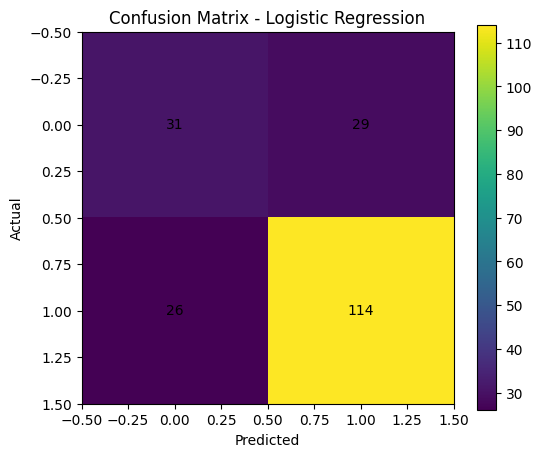

In [17]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [18]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [19]:
rf_pred = rf_model.predict(X_test)

rf_probability = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions completed!")
print("Number of predictions:", len(rf_pred))

Random Forest predictions completed!
Number of predictions: 200


In [20]:
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_probability)

print("Random Forest Evaluation Results")
print("--------------------------------")
print("Precision :", round(rf_precision, 4))
print("Recall    :", round(rf_recall, 4))
print("F1-Score  :", round(rf_f1, 4))
print("ROC-AUC   :", round(rf_roc_auc, 4))

Random Forest Evaluation Results
--------------------------------
Precision : 0.7962
Recall    : 0.8929
F1-Score  : 0.8418
ROC-AUC   : 0.8057


In [21]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1-Score": [f1, rf_f1],
    "ROC-AUC": [roc_auc, rf_roc_auc]
})

print(comparison.round(4))

                 Model  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.7972  0.8143    0.8057   0.7492
1        Random Forest     0.7962  0.8929    0.8418   0.8057


Random Forest Confusion Matrix:
[[ 28  32]
 [ 15 125]]


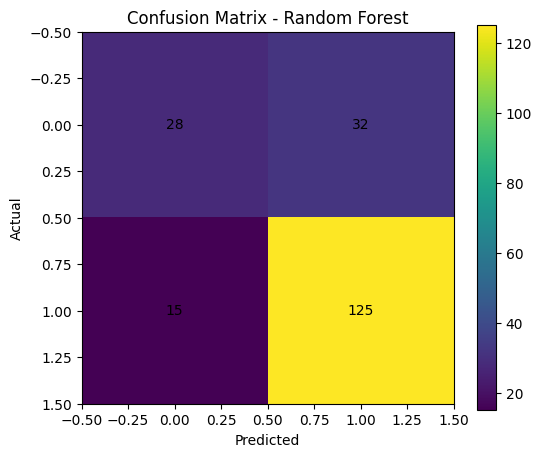

In [22]:
rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

plt.figure(figsize=(6, 5))
plt.imshow(rf_cm)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, rf_cm[i, j], ha="center", va="center")

plt.show()

In [23]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(feature_importance.head(10))

Top 10 Important Features:
      Feature  Importance
3   Feature_4    0.124543
1   Feature_2    0.114245
0   Feature_1    0.110916
9  Feature_10    0.106524
5   Feature_6    0.057247
2   Feature_3    0.056278
8   Feature_9    0.053821
4   Feature_5    0.047696
7   Feature_8    0.047003
6   Feature_7    0.038369


In [24]:
final_results = comparison.round(4)

print("FINAL MODEL RESULTS")
print("===================")
print(final_results.to_string(index=False))

FINAL MODEL RESULTS
              Model  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     0.7972  0.8143    0.8057   0.7492
      Random Forest     0.7962  0.8929    0.8418   0.8057


In [29]:
# Feature Engineering

df["Feature_Interaction"] = df["Feature_1"] * df["Feature_2"]

print("Feature engineering completed successfully!")
print(df[["Feature_1", "Feature_2", "Feature_Interaction"]].head())

Feature engineering completed successfully!
   Feature_1  Feature_2  Feature_Interaction
0          1          6                    6
1          2         48                   96
2          4         12                   48
3          1         42                   42
4          1         24                   24
